In [2]:
# Importar pandas y cargar la base Amazon
import pandas as pd

data = pd.read_excel("Copia de Amazon.xlsx")

data.head()

,Unnamed: 0,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas
0,Adam,205,3,345,235,24,23,26,21,17
1,Anna,9,15,315,33,25,4,42,215,28
2,Bernard,17,26,285,3,43,27,41,26,33
3,Edward,135,5,355,295,18,23,39,195,17
4,Emilia,3,45,48,39,34,46,225,34,43


In [3]:
# Revisar la base de datos Amazon
print("Dimensiones:", data.shape)

print("\nTipos de variables:")
print(data.dtypes)

print("\nValores faltantes:")
print(data.isnull().sum())

Dimensiones: (100, 10)

Tipos de variables:
Unnamed: 0             str
Velocidad Entrega    int64
Precio               int64
Durabilidad          int64
Imagen Producto      int64
Valor Educativo      int64
Servicio Retorno     int64
Tamano Paquete       int64
Calidad Producto     int64
Numero Estrellas     int64
dtype: object

Valores faltantes:
Unnamed: 0           0
Velocidad Entrega    0
Precio               0
Durabilidad          0
Imagen Producto      0
Valor Educativo      0
Servicio Retorno     0
Tamano Paquete       0
Calidad Producto     0
Numero Estrellas     0
dtype: int64


count    100.000000
mean      28.220000
std       11.720292
min        1.000000
25%       22.750000
50%       30.000000
75%       36.500000
max       48.000000
Name: Numero Estrellas, dtype: float64


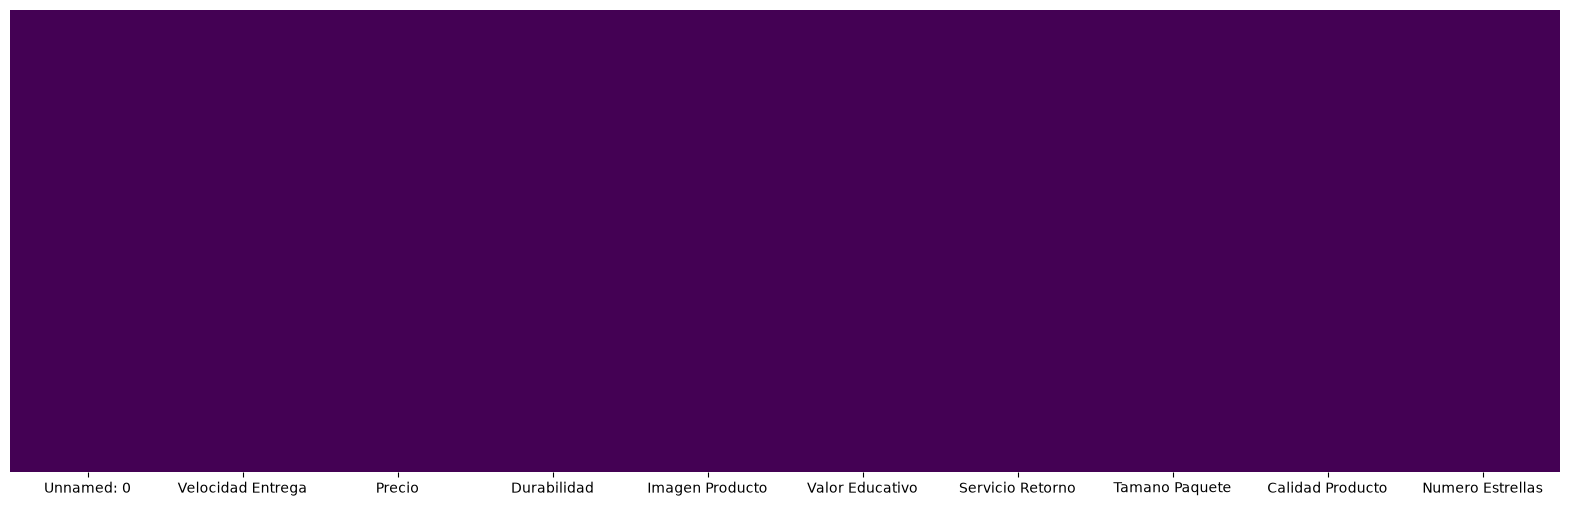

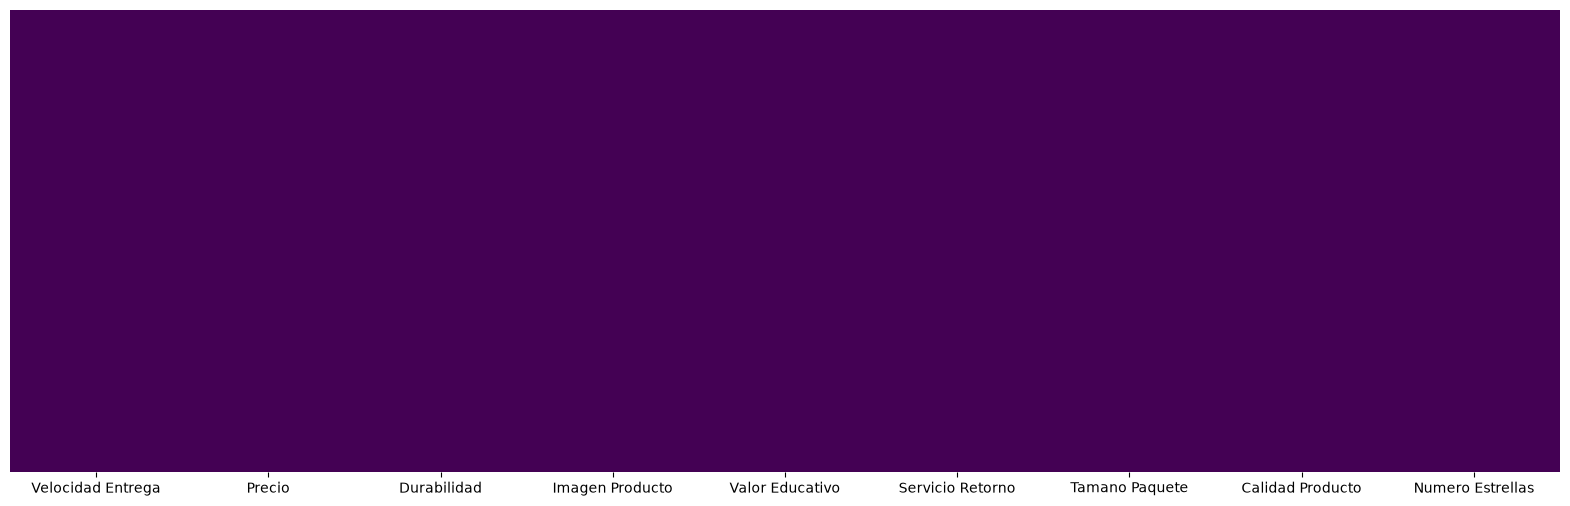

(100, 9)


In [21]:
# Examining the response variable
print(data["Numero Estrellas"].describe())

import matplotlib.pyplot as plt
import seaborn as sns

# Valores faltantes antes de la limpieza
plt.figure(figsize=(20, 6))
sns.heatmap(data.isnull(), yticklabels=False,
            cbar=False, cmap='viridis')
plt.show()

# Remove categorical features
amazon = data.drop(["Unnamed: 0"], axis=1)

# Remove rows with any missing values
amazon.dropna(inplace=True)

# Valores faltantes después de la limpieza
plt.figure(figsize=(20, 6))
sns.heatmap(amazon.isnull(), yticklabels=False,
            cbar=False, cmap='viridis')
plt.show()

# Checking the shape
print(amazon.shape)

In [4]:
# Separar las variables independientes y dependiente
X = data.drop(columns=["Unnamed: 0", "Numero Estrellas"])
y = data["Numero Estrellas"]

print("Variables independientes:", X.shape)
print("Variable dependiente:", y.shape)

print("\nVariables utilizadas:")
print(X.columns)

Variables independientes: (100, 8)
Variable dependiente: (100,)

Variables utilizadas:
Index(['Velocidad Entrega', 'Precio', 'Durabilidad', 'Imagen Producto',
       'Valor Educativo', 'Servicio Retorno', 'Tamano Paquete',
       'Calidad Producto'],
      dtype='str')


In [5]:
# Dividir los datos en entrenamiento y prueba
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=1
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (70, 8)
Datos de prueba: (30, 8)


In [6]:
# Modelo de regresión lineal
from sklearn.linear_model import LinearRegression

linreg = LinearRegression()
linreg.fit(X_train, y_train)

print("INTERCEPT:", linreg.intercept_)
print("COEFFICIENTS:", linreg.coef_)

INTERCEPT: 5.243563827855251
COEFFICIENTS: [ 0.04168531  0.00181023 -0.00453656  0.00625677  0.41960111  0.19191838
  0.01277515  0.01699507]


In [7]:
# Realizar predicciones
y_pred = linreg.predict(X_test)

# Calcular R², MAE, MSE y RMSE
import numpy as np
from sklearn.metrics import r2_score
from sklearn import metrics

print("R-Square Value:", r2_score(y_test, y_pred))
print("\n")
print("mean_absolute_error:", metrics.mean_absolute_error(y_test, y_pred))
print("\n")
print("mean_squared_error:", metrics.mean_squared_error(y_test, y_pred))
print("\n")
print("root_mean_squared_error:", np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

R-Square Value: 0.08251982473231534


mean_absolute_error: 8.642601566366274


mean_squared_error: 133.81346414037483


root_mean_squared_error: 11.567776974871828


In [8]:
# Ridge Regression con alpha = 0
from sklearn.linear_model import Ridge

ridgereg = Ridge(alpha=0)
ridgereg.fit(X_train, y_train)

y_pred = ridgereg.predict(X_test)

print("R-Square Value:", r2_score(y_test, y_pred))
print("\n")
print("mean_absolute_error:", metrics.mean_absolute_error(y_test, y_pred))
print("\n")
print("mean_squared_error:", metrics.mean_squared_error(y_test, y_pred))
print("\n")
print("root_mean_squared_error:", np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

R-Square Value: 0.082519824732315


mean_absolute_error: 8.642601566366277


mean_squared_error: 133.81346414037486


root_mean_squared_error: 11.56777697487183


In [9]:
# Ridge Regression con alpha = 0.1
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

ridgereg = make_pipeline(
    StandardScaler(),
    Ridge(alpha=0.1)
)

ridgereg.fit(X_train, y_train)

y_pred = ridgereg.predict(X_test)

print("R-Square Value:", r2_score(y_test, y_pred))
print("\n")
print("mean_absolute_error:", metrics.mean_absolute_error(y_test, y_pred))
print("\n")
print("mean_squared_error:", metrics.mean_squared_error(y_test, y_pred))
print("\n")
print("root_mean_squared_error:", np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

R-Square Value: 0.08289590560253846


mean_absolute_error: 8.640959301112014


mean_squared_error: 133.7586131633204


root_mean_squared_error: 11.565405879748466


In [10]:
# Examinar los coeficientes de Ridge
print(ridgereg.named_steps["ridge"].coef_)

[ 3.92696401  0.12218117 -0.86176292  0.74502577  4.55029933  1.90231137
  2.03531967  1.88586109]


In [11]:
# Crear un arreglo de valores alpha
alpha_range = 10.**np.arange(-2, 3)

alpha_range

array([1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02])

In [12]:
# Seleccionar el mejor alpha con RidgeCV
from sklearn.linear_model import RidgeCV

ridgeregcv = make_pipeline(
    StandardScaler(),
    RidgeCV(
        alphas=alpha_range,
        scoring="neg_mean_squared_error"
    )
)

ridgeregcv.fit(X_train, y_train)

print("Mejor alpha:", ridgeregcv.named_steps["ridgecv"].alpha_)

Mejor alpha: 10.0


In [13]:
# Predicciones con el mejor alpha
y_pred = ridgeregcv.predict(X_test)

# Calcular R², MAE, MSE y RMSE
print("R-Square Value:", r2_score(y_test, y_pred))
print("\n")
print("mean_absolute_error:", metrics.mean_absolute_error(y_test, y_pred))
print("\n")
print("mean_squared_error:", metrics.mean_squared_error(y_test, y_pred))
print("\n")
print("root_mean_squared_error:", np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

R-Square Value: 0.1094742686177399


mean_absolute_error: 8.537731447035394


mean_squared_error: 129.88218844906774


root_mean_squared_error: 11.396586701686946


In [14]:
# Lasso Regression con alpha = 0.001
from sklearn.linear_model import Lasso

lassoreg = make_pipeline(
    StandardScaler(),
    Lasso(alpha=0.001)
)

lassoreg.fit(X_train, y_train)

print(lassoreg.named_steps["lasso"].coef_)

[ 3.93097701  0.11928348 -0.86312625  0.74619173  4.55608029  1.90308373
  2.03877858  1.88736392]


In [15]:
# Lasso Regression con alpha = 0.01
lassoreg = make_pipeline(
    StandardScaler(),
    Lasso(alpha=0.01)
)

lassoreg.fit(X_train, y_train)

print(lassoreg.named_steps["lasso"].coef_)

[ 3.92278665  0.11561544 -0.85089925  0.73383317  4.54674794  1.89330095
  2.03310922  1.87604045]


In [16]:
# Predicciones con Lasso
y_pred = lassoreg.predict(X_test)

# Calcular R², MAE, MSE y RMSE
print("R-Square Value:", r2_score(y_test, y_pred))
print("\n")
print("mean_absolute_error:", metrics.mean_absolute_error(y_test, y_pred))
print("\n")
print("mean_squared_error:", metrics.mean_squared_error(y_test, y_pred))
print("\n")
print("root_mean_squared_error:", np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

R-Square Value: 0.08436938862693022


mean_absolute_error: 8.6368774748128


mean_squared_error: 133.54370730141625


root_mean_squared_error: 11.556111253419822


In [17]:
# Seleccionar el mejor alpha con LassoCV
from sklearn.linear_model import LassoCV

lassoregcv = make_pipeline(
    StandardScaler(),
    LassoCV(alphas=100, random_state=1)
)

lassoregcv.fit(X_train, y_train)

print("Alpha:", lassoregcv.named_steps["lassocv"].alpha_)

Alpha: 0.8854841600543769


In [18]:
# Examinar los coeficientes de LassoCV
print(lassoregcv.named_steps["lassocv"].coef_)

[ 3.12600917  0.         -0.          0.          3.68298397  1.01709046
  1.32365149  0.82131398]


In [19]:
# Predicciones con el mejor alpha de LassoCV
y_pred = lassoregcv.predict(X_test)

# Calcular R², MAE, MSE y RMSE
print("R-Square Value:", r2_score(y_test, y_pred))
print("\n")
print("mean_absolute_error:", metrics.mean_absolute_error(y_test, y_pred))
print("\n")
print("mean_squared_error:", metrics.mean_squared_error(y_test, y_pred))
print("\n")
print("root_mean_squared_error:", np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

R-Square Value: 0.17783679577326916


mean_absolute_error: 8.300167719827913


mean_squared_error: 119.91158982179732


root_mean_squared_error: 10.950415052489898


In [20]:
# Comparación final de los modelos
modelos = {
    "Regresion Lineal": linreg,
    "Ridge (alpha=0.1)": ridgereg,
    "RidgeCV": ridgeregcv,
    "Lasso (alpha=0.01)": lassoreg,
    "LassoCV": lassoregcv
}

resultados = []

for nombre, modelo in modelos.items():
    pred = modelo.predict(X_test)

    resultados.append({
        "Modelo": nombre,
        "R2": r2_score(y_test, pred),
        "MAE": metrics.mean_absolute_error(y_test, pred),
        "MSE": metrics.mean_squared_error(y_test, pred),
        "RMSE": np.sqrt(metrics.mean_squared_error(y_test, pred))
    })

comparacion = pd.DataFrame(resultados)
comparacion.round(4)

,Modelo,R2,MAE,MSE,RMSE
0,Regresion Lineal,0.0825,8.6426,133.8135,11.5678
1,Ridge (alpha=0.1),0.0829,8.6410,133.7586,11.5654
2,RidgeCV,0.1095,8.5377,129.8822,11.3966
3,Lasso (alpha=0.01),0.0844,8.6369,133.5437,11.5561
4,LassoCV,0.1778,8.3002,119.9116,10.9504
